# Customer Churn Analysis & Customer Intelligence
**Author:** Gaurav Kalamkhede &nbsp;|&nbsp; **Domain:** OTT / Subscription streaming &nbsp;|&nbsp; **Stack:** SQL (SQLite) · Python · pandas · NumPy · Matplotlib · Seaborn

---

### Business problem
In a competitive OTT market, keeping a subscriber is far cheaper than acquiring a new one. The business wants to know:

* **Who** is leaving (and who is likely to leave next),
* **Why** they are leaving (plan, contract, support experience, price, competition), and
* **When** churn happens, so retention campaigns can be timed correctly.

### What I do in this notebook
1. Build a SQLite database from the raw Excel export and pull the three tables into pandas with SQL.
2. Run data-quality checks and clean each table (types, naming, standardisation, missing values, duplicates).
3. Engineer features: churn flag, tenure, customer age, complaint count, escalation flag and a churn-risk tier.
4. Join the tables into one customer-level master table (checking row counts before/after every join).
5. Calculate 20+ KPIs: churn & retention rate, ARPU, tenure, MRR lost, CLTV lost, escalation rate, revenue at risk…
6. Segment churn by plan, contract, acquisition channel, state, gender and age group, and cross-check KPIs in pure SQL.
7. Visualise the findings and translate them into business recommendations.

## 0. Setup

In [1]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="white")

# project paths (notebook lives in /notebooks)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_XLSX = ROOT / "data" / "raw" / "customer_churn_data_raw.xlsx"
DB_PATH = ROOT / "data" / "customer_churn.db"
PROCESSED_DIR = ROOT / "data" / "processed"
CHART_DIR = ROOT / "images" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

# fixed snapshot date -> tenure and age stay reproducible on every run
SNAPSHOT_DATE = pd.Timestamp("2025-12-31")

# muted palette: one dark accent for the segment that matters, greys for everything else
ACCENT, LIGHT_GREY, NEUTRAL, MUTED, MEDIUM = "#2F4A6D", "#B8C0C8", "#B8C0C8", "#D5DAE0", "#7D8B99"

## 1. Data import — Excel to SQLite to pandas
The raw export is an Excel workbook with one sheet per source table. I load each sheet into a SQLite table so the rest of the analysis works off a real relational database, exactly like pulling from a production warehouse.

In [2]:
# build the SQLite database from the raw workbook (one table per sheet)
with sqlite3.connect(DB_PATH) as conn:
    for sheet in pd.ExcelFile(RAW_XLSX).sheet_names:
        pd.read_excel(RAW_XLSX, sheet_name=sheet).to_sql(sheet, conn, if_exists="replace", index=False)
        print(f"Loaded sheet -> table: {sheet}")

Loaded sheet -> table: db_customer
Loaded sheet -> table: db_subscription
Loaded sheet -> table: db_support


In [3]:
# list tables and their columns using SQLite metadata (sqlite_master + PRAGMA)
conn = sqlite3.connect(DB_PATH)
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)

for table_name in tables["name"]:
    cols = pd.read_sql(f"PRAGMA table_info({table_name});", conn)["name"].tolist()
    rows = pd.read_sql(f"SELECT COUNT(*) AS n FROM {table_name};", conn)["n"][0]
    print(f"{table_name:<16} rows={rows:<3} columns={cols}")

db_customer      rows=21  columns=['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']
db_subscription  rows=21  columns=['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']
db_support       rows=9   columns=['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [4]:
# pull every table into its own DataFrame with a SQL query
df_customer = pd.read_sql("SELECT * FROM db_customer", conn)
df_subscription = pd.read_sql("SELECT * FROM db_subscription", conn)
df_support = pd.read_sql("SELECT * FROM db_support", conn)
conn.close()

df_customer.shape, df_subscription.shape, df_support.shape

((21, 8), (21, 11), (9, 6))

## 2. Data quality checks
Before cleaning anything I profile each table: nulls, duplicates and inconsistent category labels.

In [5]:
def quality_report(df, name):
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })
    print(f"{name}: {df.shape[0]} rows | duplicate customerid rows = {df['customerid'].duplicated().sum()}")
    return report

quality_report(df_customer, "db_customer")

db_customer: 21 rows | duplicate customerid rows = 0


,dtype,nulls,null_%,unique
customerid,object,0,0.0,21
name,object,0,0.0,21
country,object,3,14.3,2
state,object,0,0.0,9
gender,object,0,0.0,4
dob,object,0,0.0,21
interests,object,17,81.0,4
pincode,object,21,100.0,0


In [6]:
quality_report(df_subscription, "db_subscription")

db_subscription: 21 rows | duplicate customerid rows = 0


,dtype,nulls,null_%,unique
customerid,object,0,0.0,21
subscription_start_date,object,0,0.0,21
subscription_type,object,0,0.0,3
renewal_date,object,0,0.0,21
plan_type,object,0,0.0,3
contract_type,object,0,0.0,2
cancellation_date,object,15,71.4,6
cancellation_reason,object,15,71.4,5
monthly_charges,float64,0,0.0,10
cltv,int64,0,0.0,21


In [7]:
quality_report(df_support, "db_support")

db_support: 9 rows | duplicate customerid rows = 2


,dtype,nulls,null_%,unique
customerid,object,0,0.0,7
complaint_date,object,0,0.0,8
escalations,object,0,0.0,2
csat_score,int64,0,0.0,6
col_1,object,9,100.0,0
comment,object,5,55.6,4


In [8]:
# inconsistent labels spotted during profiling
print("gender            :", df_customer["gender"].unique())
print("subscription_type :", df_subscription["subscription_type"].unique())
print("escalations       :", df_support["escalations"].unique())

gender            : ['Male' 'Female' 'Women' 'Men']
subscription_type : ['Refferal' 'Paid' 'Organic']
escalations       : ['N' 'Y']


**Issues found**

| Table | Issue | Fix |
|---|---|---|
| customer | `name` is ambiguous | rename to `customer_name` |
| customer | `interests` (81% null) and `pincode` (100% null) carry no information | drop |
| customer | `dob` stored as text | convert to datetime |
| customer | gender has 4 labels (`Male`, `Female`, `Men`, `Women`) | standardise to Male/Female |
| customer | 3 rows missing `country` | infer from the state → country mapping |
| subscription | dates stored as text, typo `Refferal` | convert to datetime, fix label |
| support | `col_1` empty, `comment` free text with typos | drop |
| support | customers with more than one complaint → would duplicate rows on join | aggregate to one row per customer |

## 3. Data cleaning
### 3.1 Customer table

In [9]:
df_customer = df_customer.rename(columns={"name": "customer_name"})
df_customer = df_customer.drop(columns=["interests", "pincode"])
df_customer["dob"] = pd.to_datetime(df_customer["dob"])
df_customer["gender"] = df_customer["gender"].replace({"Men": "Male", "Women": "Female"})
df_customer["customer_name"] = df_customer["customer_name"].str.title()

df_customer["gender"].value_counts()

gender
Female    12
Male       9
Name: count, dtype: int64

In [10]:
# rows with missing country
df_customer[df_customer["country"].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,Durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,Maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,Chitra,None,Telangana,Female,2004-12-01


In [11]:
# every state belongs to exactly one country -> build the mapping from complete rows and fill the gaps
state_country_map = df_customer.dropna(subset=["country"]).set_index("state")["country"].to_dict()
df_customer["country"] = df_customer["country"].fillna(df_customer["state"].map(state_country_map))

print("Missing country after fix:", df_customer["country"].isna().sum())
df_customer.head()

Missing country after fix: 0


,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,Keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,Raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,Lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,Mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,Mira,India,Delhi,Female,1990-05-05


### 3.2 Subscription table

In [12]:
date_cols = ["subscription_start_date", "renewal_date", "cancellation_date"]
df_subscription[date_cols] = df_subscription[date_cols].apply(pd.to_datetime)
df_subscription["subscription_type"] = df_subscription["subscription_type"].replace({"Refferal": "Referral"})

df_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


### 3.3 Support table

In [13]:
df_support = df_support.drop(columns=["col_1", "comment"])
df_support["complaint_date"] = pd.to_datetime(df_support["complaint_date"])
df_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [14]:
# 9 complaint rows but only 7 customers -> joining as-is would duplicate subscribers.
# Aggregate to one row per customer: total complaints, escalated at least once, latest CSAT.
df_support["complaint_count"] = df_support.groupby("customerid")["customerid"].transform("count")
df_support["escalations"] = (df_support.groupby("customerid")["escalations"]
                                        .transform(lambda s: "Y" if (s == "Y").any() else "N"))
df_support = df_support.sort_values("complaint_date").drop_duplicates("customerid", keep="last")

print("rows:", len(df_support), "| unique customers:", df_support["customerid"].nunique())
df_support

rows: 7 | unique customers: 7


,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,Y,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


## 4. Feature engineering & joins

In [15]:
# churn flag: a customer has churned if a cancellation date exists
df_subscription["churn_flag"] = np.where(df_subscription["cancellation_date"].notna(), 1, 0)

# LEFT JOIN subscription -> customer -> support (subscription is the customer base)
print("subscription rows before join:", len(df_subscription))
df = (df_subscription
        .merge(df_customer, on="customerid", how="left")
        .merge(df_support, on="customerid", how="left"))
print("master rows after join       :", len(df))
assert len(df) == len(df_subscription), "join created duplicate rows"

subscription rows before join: 21
master rows after join       : 21


In [16]:
# tenure: days from start until cancellation (churned) or until the snapshot date (active)
end_date = df["cancellation_date"].fillna(SNAPSHOT_DATE)
df["tenure_days"] = (end_date - df["subscription_start_date"]).dt.days

# customer age and age band
df["age"] = ((SNAPSHOT_DATE - df["dob"]).dt.days // 365.25).astype(int)
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 100], labels=["<25", "25-34", "35-44", "45+"], right=False)

# support features: customers without complaints get 0
df["complaint_count"] = df["complaint_count"].fillna(0).astype(int)
df["escalation_flag"] = np.where(df["escalations"] == "Y", 1, 0)

# churn-risk tier from the model churn score
df["churn_risk"] = np.select(
    [df["churn_score"] < 50, df["churn_score"] < 70, df["churn_score"] >= 70],
    ["Low", "Medium", "High"], default="Unknown")

df["cancellation_month"] = df["cancellation_date"].dt.to_period("M")

df[["customerid", "plan_type", "contract_type", "churn_flag", "tenure_days", "age", "age_group",
    "complaint_count", "escalation_flag", "churn_score", "churn_risk"]].head(8)

,customerid,plan_type,contract_type,churn_flag,tenure_days,age,age_group,complaint_count,escalation_flag,churn_score,churn_risk
0,0002-ORFBO,Standard,Annual,0,1752,43,35-44,0,0,12,Low
1,0003-MKNFE,Premium,Annual,1,1501,30,25-34,2,1,91,High
2,0004-TLHLJ,Basic,Monthly,0,1137,47,45+,0,0,34,Low
3,0011-IGKFF,Premium,Annual,0,2427,24,<25,0,0,8,Low
4,0013-EXCHZ,Standard,Monthly,1,419,35,35-44,1,1,88,High
5,0013-MHZWF,Standard,Annual,0,1292,37,35-44,1,0,22,Low
6,0013-SMEOE,Basic,Monthly,1,1142,49,45+,1,0,79,High
7,0014-BMAQU,Premium,Annual,0,2147,26,25-34,0,0,5,Low


In [17]:
# export the clean customer-level master table
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.drop(columns=["cancellation_month"]).to_csv(PROCESSED_DIR / "churn_master_clean.csv", index=False)
print("Saved: data/processed/churn_master_clean.csv", df.shape)

Saved: data/processed/churn_master_clean.csv (21, 27)


## 5. KPI analysis

In [18]:
churned = df[df["churn_flag"] == 1]
active = df[df["churn_flag"] == 0]

churn_rate = df["churn_flag"].mean() * 100
retention_rate = 100 - churn_rate
arpu = df["monthly_charges"].mean()
arpu_active = active["monthly_charges"].mean()
avg_tenure = df["tenure_days"].mean()
total_mrr = df["monthly_charges"].sum()
mrr_lost = churned["monthly_charges"].sum()
cltv_lost = churned["cltv"].sum()
escalation_rate = df["escalation_flag"].mean() * 100
avg_complaints = df["complaint_count"].sum() / df["customerid"].nunique()
corr_esc_churn = df["escalation_flag"].corr(df["churn_flag"])

kpis = pd.Series({
    "Total customers": len(df),
    "Churned customers": len(churned),
    "Churn rate (%)": round(churn_rate, 2),
    "Retention rate (%)": round(retention_rate, 2),
    "ARPU - all customers (Rs)": round(arpu, 2),
    "ARPU - active customers (Rs)": round(arpu_active, 2),
    "Avg tenure (days)": round(avg_tenure),
    "Total monthly revenue / MRR (Rs)": round(total_mrr, 2),
    "MRR lost to churn (Rs)": round(mrr_lost, 2),
    "MRR lost (%)": round(mrr_lost / total_mrr * 100, 2),
    "CLTV lost (Rs)": cltv_lost,
    "Escalation rate (%)": round(escalation_rate, 2),
    "Avg complaints per customer": round(avg_complaints, 2),
    "Correlation escalation vs churn": round(corr_esc_churn, 2),
}, dtype=object)
kpis.to_frame("value")

,value
Total customers,21
Churned customers,6
Churn rate (%),28.57
Retention rate (%),71.43
ARPU - all customers (Rs),18.85
ARPU - active customers (Rs),21.46
Avg tenure (days),1355
Total monthly revenue / MRR (Rs),395.79
MRR lost to churn (Rs),73.94
MRR lost (%),18.68


In [19]:
# churn rate with vs without an escalated complaint
df.groupby("escalation_flag")["churn_flag"].agg(customers="count", churn_rate=lambda s: round(s.mean() * 100, 2))

,customers,churn_rate
escalation_flag,,
0,16,6.25
1,5,100.00


In [20]:
# contract type: monthly vs annual
contract = df.groupby("contract_type")["churn_flag"].mean().mul(100).round(2)
print(contract)
print(f"\nMonthly subscribers churn {contract['Monthly'] / contract['Annual']:.1f}x more than annual subscribers")

contract_type
Annual      8.33
Monthly    55.56
Name: churn_flag, dtype: float64

Monthly subscribers churn 6.7x more than annual subscribers


In [21]:
# revenue AT RISK: active customers whose churn score puts them in the Medium/High tier
at_risk = active[active["churn_risk"].isin(["High", "Medium"])]
print(f"Active customers at risk : {len(at_risk)}")
print(f"MRR at risk (Rs)         : {at_risk['monthly_charges'].sum():.2f}")
print(f"CLTV at risk (Rs)        : {at_risk['cltv'].sum()}")
at_risk[["customerid", "customer_name", "plan_type", "contract_type", "monthly_charges", "cltv", "churn_score", "churn_risk"]]

Active customers at risk : 2
MRR at risk (Rs)         : 34.98
CLTV at risk (Rs)        : 1190


,customerid,customer_name,plan_type,contract_type,monthly_charges,cltv,churn_score,churn_risk
15,0020-INWCK,Parvati,Standard,Monthly,13.99,640,58,Medium
16,0020-JDNXP,Rikim,Premium,Annual,20.99,550,62,Medium


In [22]:
# lifetime value gap between retained and churned customers
df.groupby("churn_flag")["cltv"].agg(["count", "mean", "median", "sum"]).rename(index={0: "Retained", 1: "Churned"}).round(1)

,count,mean,median,sum
churn_flag,,,,
Retained,15,1016.5,790.0,15247
Churned,6,341.2,212.5,2047


## 6. Segment analysis
One reusable function gives churn rate, customer count and revenue for any dimension.

In [23]:
def segment(by):
    return (df.groupby(by, observed=True)
              .agg(customers=("customerid", "nunique"),
                   churned=("churn_flag", "sum"),
                   churn_rate_pct=("churn_flag", lambda s: round(s.mean() * 100, 2)),
                   monthly_revenue=("monthly_charges", "sum"),
                   cltv=("cltv", "sum"))
              .sort_values("churn_rate_pct", ascending=False))

segment("plan_type")

,customers,churned,churn_rate_pct,monthly_revenue,cltv
plan_type,,,,,
Basic,5,3,60.00,52.95,977
Standard,9,2,22.22,123.91,5302
Premium,7,1,14.29,218.93,11015


In [24]:
segment("subscription_type")   # acquisition channel

,customers,churned,churn_rate_pct,monthly_revenue,cltv
subscription_type,,,,,
Referral,6,5,83.33,74.94,1524
Paid,6,1,16.67,174.94,7410
Organic,9,0,0.00,145.91,8360


In [25]:
segment(["country", "state"])

customers  churned  churn_rate_pct  monthly_revenue  \
country state                                                                
India   Karnataka              2        2          100.00            20.98   
        Meghalaya              3        2           66.67            42.97   
        Telangana              2        1           50.00            30.98   
        Delhi                  4        1           25.00            52.96   
        Maharashtra            3        0            0.00            50.97   
        Nagaland               1        0            0.00            22.99   
        Rajasthan              2        0            0.00            36.98   
        Uttar Pradesh          2        0            0.00           115.98   
Nepal   Kathmandu              2        0            0.00            20.98   

                       cltv  
country state                
India   Karnataka      1420  
        Meghalaya       940  
        Telangana      1022  
        Delhi          1765  
        Maharashtra    3027  
        Nagaland       1725  
        Rajasthan      2680  
        Uttar Pradesh  4140  
Nepal   Kathmandu       575

In [26]:
segment("age_group")

,customers,churned,churn_rate_pct,monthly_revenue,cltv
age_group,,,,,
35-44,7,3,42.86,98.93,2734
25-34,8,2,25.00,136.92,8440
45+,4,1,25.00,122.96,3415
<25,2,0,0.00,36.98,2705


In [27]:
segment("gender")

,customers,churned,churn_rate_pct,monthly_revenue,cltv
gender,,,,,
Female,12,4,33.33,159.88,5825
Male,9,2,22.22,235.91,11469


In [28]:
# cancellation reasons
df["cancellation_reason"].value_counts().to_frame("customers")

,customers
cancellation_reason,
Switched to competitor,2
Too expensive,1
Not enough content,1
Poor streaming quality,1
Forgot to cancel trial,1


In [29]:
# save every segment table for reporting
for by in ["plan_type", "contract_type", "subscription_type", "state", "gender", "age_group", "churn_risk"]:
    segment(by).reset_index().to_csv(PROCESSED_DIR / f"segment_{by}.csv", index=False)

## 7. Cross-checking KPIs in SQL
To validate the pandas logic I recompute the headline KPIs directly in SQLite with joins, `CASE WHEN` and `GROUP BY`.

In [30]:
conn = sqlite3.connect(DB_PATH)

kpi_sql = """
SELECT COUNT(*)                                                      AS customers,
       SUM(CASE WHEN cancellation_date IS NOT NULL THEN 1 ELSE 0 END) AS churned,
       ROUND(100.0 * AVG(CASE WHEN cancellation_date IS NOT NULL THEN 1 ELSE 0 END), 2) AS churn_rate_pct,
       ROUND(AVG(monthly_charges), 2)                                AS arpu,
       ROUND(SUM(CASE WHEN cancellation_date IS NOT NULL THEN monthly_charges END), 2) AS mrr_lost,
       SUM(CASE WHEN cancellation_date IS NOT NULL THEN cltv END)    AS cltv_lost
FROM db_subscription;
"""
pd.read_sql(kpi_sql, conn)

,customers,churned,churn_rate_pct,arpu,mrr_lost,cltv_lost
0,21,6,28.57,18.85,73.94,2047


In [31]:
plan_sql = """
SELECT s.plan_type,
       s.contract_type,
       COUNT(*)                                                             AS customers,
       ROUND(100.0 * AVG(CASE WHEN s.cancellation_date IS NOT NULL THEN 1 ELSE 0 END), 1) AS churn_rate_pct,
       ROUND(SUM(s.monthly_charges), 2)                                     AS monthly_revenue
FROM db_subscription s
GROUP BY s.plan_type, s.contract_type
ORDER BY churn_rate_pct DESC;
"""
pd.read_sql(plan_sql, conn)

,plan_type,contract_type,customers,churn_rate_pct,monthly_revenue
0,Basic,Monthly,4,75.0,45.96
1,Standard,Monthly,5,40.0,63.95
2,Premium,Annual,7,14.3,218.93
3,Basic,Annual,1,0.0,6.99
4,Standard,Annual,4,0.0,59.96


In [32]:
state_sql = """
SELECT c.state,
       COUNT(*)                                                                AS customers,
       SUM(CASE WHEN s.cancellation_date IS NOT NULL THEN 1 ELSE 0 END)        AS churned,
       ROUND(SUM(s.monthly_charges), 2)                                        AS monthly_revenue
FROM db_subscription s
LEFT JOIN db_customer c ON c.customerid = s.customerid
GROUP BY c.state
HAVING churned > 0
ORDER BY churned DESC, customers;
"""
pd.read_sql(state_sql, conn)

,state,customers,churned,monthly_revenue
0,Karnataka,2,2,20.98
1,Meghalaya,3,2,42.97
2,Telangana,2,1,30.98
3,Delhi,4,1,52.96


In [33]:
conn.close()

## 8. Visualisation
Every chart is also saved to `images/charts/` for the report and presentation.

In [34]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()

def bar(ax, series, title, threshold=40, fmt="{:.0f}%"):
    colors = [ACCENT if v >= threshold else NEUTRAL for v in series.values]
    bars = ax.bar(series.index.astype(str), series.values, color=colors, width=0.6)
    for b, v in zip(bars, series.values):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

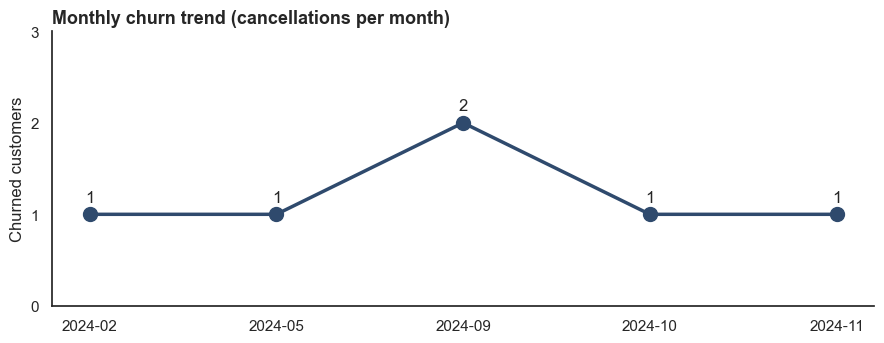

In [35]:
# 8.1 When does churn happen? Monthly churn trend
trend = churned.groupby("cancellation_month").size()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(trend.index.astype(str), trend.values, marker="o", markersize=10, linewidth=2.5, color=ACCENT)
for x, y in zip(trend.index.astype(str), trend.values):
    ax.annotate(str(y), (x, y), ha="center", xytext=(0, 9), textcoords="offset points")
ax.set_ylim(0, trend.max() + 1)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Monthly churn trend (cancellations per month)", loc="left", fontsize=13, fontweight="bold")
ax.set_ylabel("Churned customers")
ax.spines[["top", "right"]].set_visible(False)
save(fig, "01_monthly_churn_trend.png")

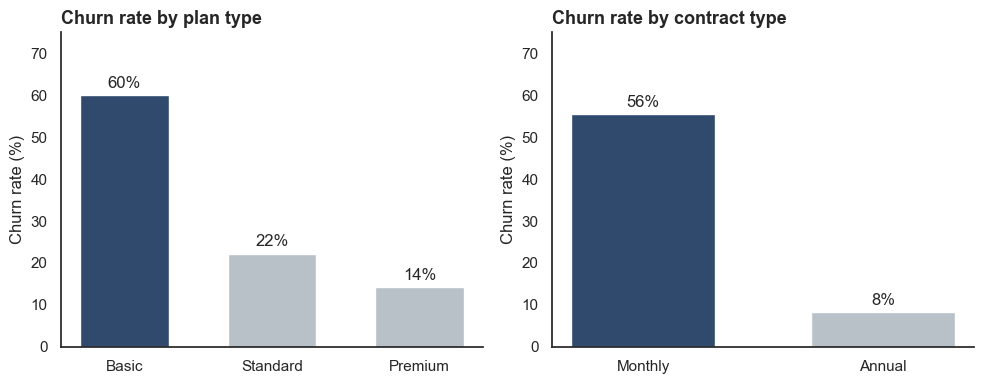

In [36]:
# 8.2 Plan and contract
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bar(axes[0], df.groupby("plan_type")["churn_flag"].mean().mul(100).reindex(["Basic", "Standard", "Premium"]), "Churn rate by plan type")
bar(axes[1], df.groupby("contract_type")["churn_flag"].mean().mul(100).reindex(["Monthly", "Annual"]), "Churn rate by contract type")
for ax in axes:
    ax.set_ylim(0, 75); ax.set_ylabel("Churn rate (%)")
save(fig, "02_churn_by_plan_contract.png")

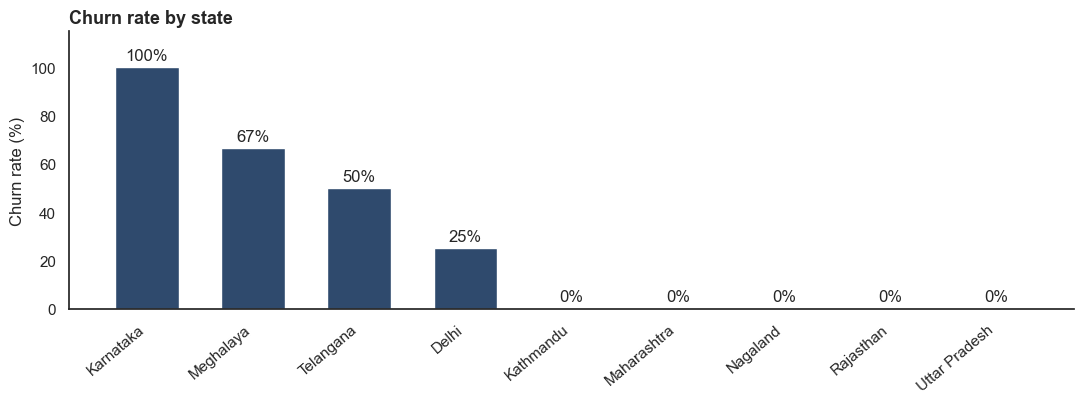

In [37]:
# 8.3 Geography
state = df.groupby("state")["churn_flag"].mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 4.2))
bar(ax, state, "Churn rate by state", threshold=1)
ax.set_ylim(0, 115); ax.set_ylabel("Churn rate (%)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "03_churn_by_state.png")

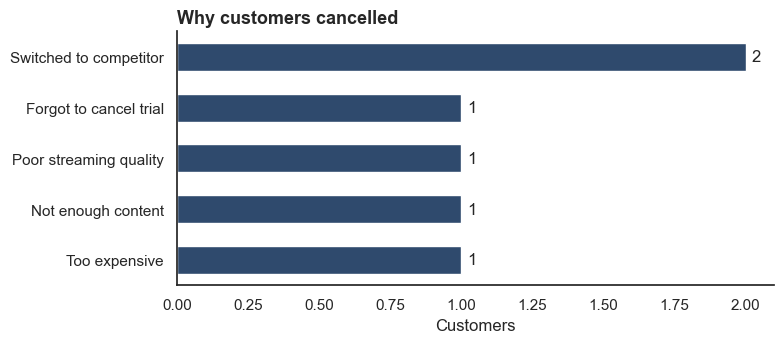

In [38]:
# 8.4 Why customers leave
reasons = df["cancellation_reason"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(reasons.index, reasons.values, color=ACCENT, height=0.55)
for i, v in enumerate(reasons.values):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_title("Why customers cancelled", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Customers"); ax.spines[["top", "right"]].set_visible(False)
save(fig, "04_cancellation_reasons.png")

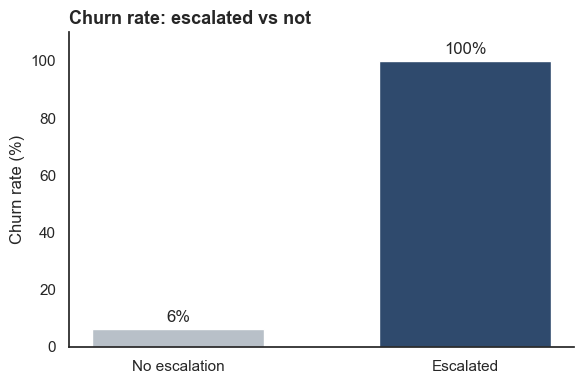

In [39]:
# 8.5 Support experience: escalated vs non-escalated customers
esc = df.groupby("escalation_flag")["churn_flag"].mean().mul(100).rename({0: "No escalation", 1: "Escalated"})
fig, ax = plt.subplots(figsize=(6, 4))
bar(ax, esc, "Churn rate: escalated vs not")
ax.set_ylim(0, 110); ax.set_ylabel("Churn rate (%)")
save(fig, "05_escalation_vs_churn.png")

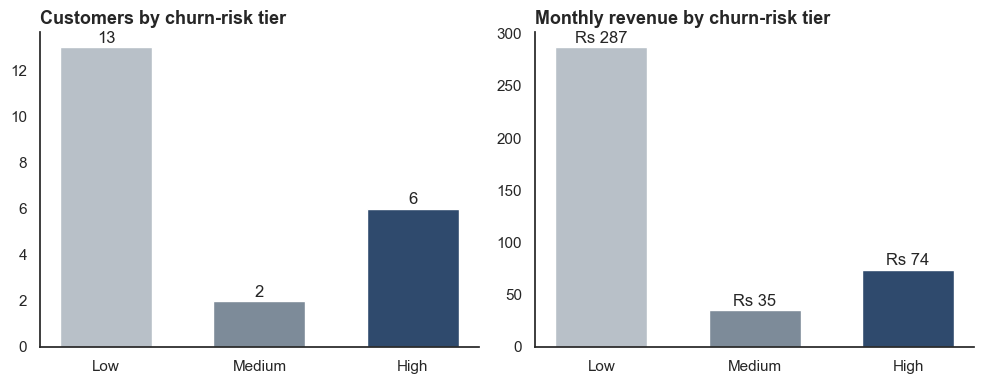

In [40]:
# 8.6 Risk tiers - how many customers and how much revenue sits in each
order = ["Low", "Medium", "High"]
risk_colors = {"Low": LIGHT_GREY, "Medium": MEDIUM, "High": ACCENT}
risk = df.groupby("churn_risk").agg(customers=("customerid", "count"), mrr=("monthly_charges", "sum")).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title, fmt in [(axes[0], "customers", "Customers by churn-risk tier", "{:.0f}"),
                            (axes[1], "mrr", "Monthly revenue by churn-risk tier", "Rs {:.0f}")]:
    bars = ax.bar(risk.index, risk[col], color=[risk_colors[r] for r in risk.index], width=0.6)
    for b, v in zip(bars, risk[col]):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), ha="center", xytext=(0, 3), textcoords="offset points")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
save(fig, "06_churn_risk_segments.png")

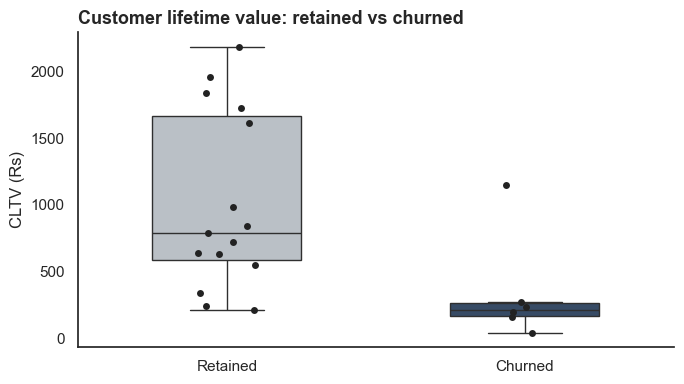

In [41]:
# 8.7 Lifetime value: who are we losing?
np.random.seed(42)  # fixed jitter so the chart is identical on every run
plot_df = df.assign(status=df["churn_flag"].map({0: "Retained", 1: "Churned"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=plot_df, x="status", y="cltv", order=["Retained", "Churned"], hue="status", legend=False,
            palette={"Retained": LIGHT_GREY, "Churned": ACCENT}, width=0.5, showfliers=False, ax=ax)
sns.stripplot(data=plot_df, x="status", y="cltv", order=["Retained", "Churned"], color="#222", size=5, ax=ax)
ax.set_title("Customer lifetime value: retained vs churned", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("CLTV (Rs)"); ax.spines[["top", "right"]].set_visible(False)
save(fig, "07_cltv_retained_vs_churned.png")

#### 8.8 Correlation matrix
Categorical columns must be encoded before computing correlation. Plain `cat.codes` assigns numbers alphabetically
(Basic=0, Premium=1, Standard=2), which breaks the natural order and gives misleading correlations, so I use **ordinal
encoding** that respects the business order (Basic < Standard < Premium, Monthly < Annual, Low < Medium < High).

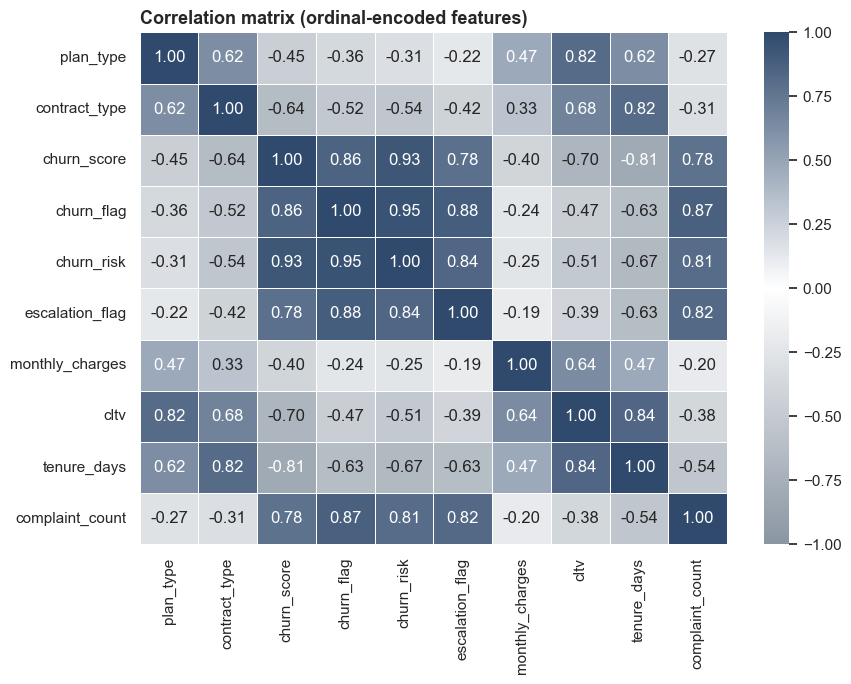

In [42]:
enc = df[["plan_type", "contract_type", "churn_score", "churn_flag", "churn_risk", "escalation_flag",
          "monthly_charges", "cltv", "tenure_days", "complaint_count"]].copy()
order_map = {"plan_type": ["Basic", "Standard", "Premium"],
             "contract_type": ["Monthly", "Annual"],
             "churn_risk": ["Low", "Medium", "High"]}
for col, order_ in order_map.items():
    enc[col] = pd.Categorical(enc[col], categories=order_, ordered=True).codes

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(enc.corr(), annot=True, fmt=".2f", cmap=sns.blend_palette(["#8A96A3", "#FFFFFF", "#2F4A6D"], as_cmap=True), vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix (ordinal-encoded features)", loc="left", fontsize=13, fontweight="bold")
save(fig, "08_correlation_heatmap.png")

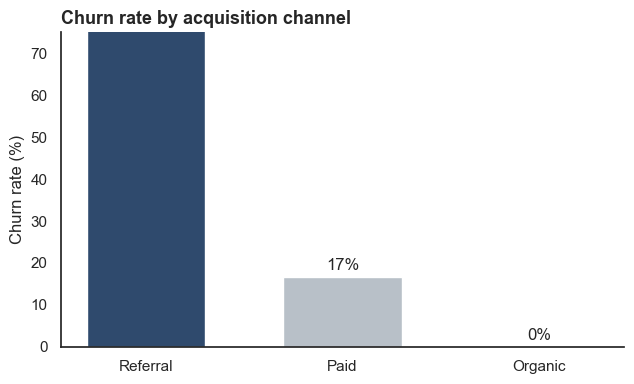

In [43]:
# 8.9 Acquisition channel
chan = df.groupby("subscription_type")["churn_flag"].mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4))
bar(ax, chan, "Churn rate by acquisition channel")
ax.set_ylim(0, 75); ax.set_ylabel("Churn rate (%)")
save(fig, "09_churn_by_channel.png")

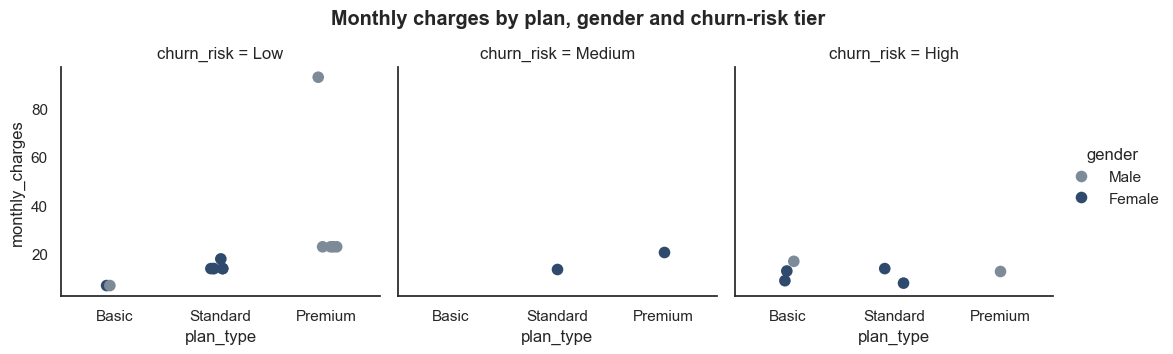

In [44]:
# 8.10 Multi-dimensional view: plan x monthly charge x gender, split by risk tier
g = sns.catplot(data=df, x="plan_type", y="monthly_charges", hue="gender", col="churn_risk",
                col_order=["Low", "Medium", "High"], order=["Basic", "Standard", "Premium"], height=3.6, s=70,
                palette={"Male": MEDIUM, "Female": ACCENT})
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Monthly charges by plan, gender and churn-risk tier", fontweight="bold")
plt.show()

## 9. Pivot tables

In [45]:
pd.pivot_table(df, index="plan_type", columns="contract_type", values="churn_flag", aggfunc="mean", margins=True).mul(100).round(1)

contract_type,Annual,Monthly,All
plan_type,,,
Basic,0.0,75.0,60.0
Premium,14.3,NaN,14.3
Standard,0.0,40.0,22.2
All,8.3,55.6,28.6


In [46]:
pd.pivot_table(df, index="plan_type",
               values=["customerid", "churn_flag", "monthly_charges", "cltv"],
               aggfunc={"customerid": "nunique", "churn_flag": "mean", "monthly_charges": "sum", "cltv": "sum"}).round(2)

,churn_flag,cltv,customerid,monthly_charges
plan_type,,,,
Basic,0.60,977,5,52.95
Premium,0.14,11015,7,218.93
Standard,0.22,5302,9,123.91


## 10. Key insights

| # | Insight | Evidence |
|---|---|---|
| 1 | **Overall churn is 28.6%** (6 of 21 subscribers); retention is 71.4% | churn_flag mean |
| 2 | **Contract type is the strongest driver** — monthly subscribers churn at **55.6% vs 8.3%** for annual (6.7×) | contract segment |
| 3 | **Support escalations predict churn** — every escalated customer churned (100% vs 6.3%); correlation **0.88** | escalation segment, heatmap |
| 4 | **Basic plan churns most (60%)** but Premium holds 55% of revenue with only 14% churn | plan segment |
| 5 | **Referral-acquired users churn at 83%**; organic users at 0% | channel segment |
| 6 | **Rs 73.94 MRR lost (18.7% of revenue)** and **Rs 2,047 CLTV lost** | KPI table |
| 7 | Churned customers had **3× lower CLTV** (Rs 341 vs Rs 1,016) — we lose short-tenure, low-value users | CLTV box plot |
| 8 | **Sep 2024 is the peak churn month**; Karnataka (2/2) and Meghalaya (2/3) are the hardest-hit states | trend, state chart |
| 9 | **2 active customers are already Medium-risk** — Rs 34.98 MRR and Rs 1,190 CLTV at risk right now | at-risk table |

## 11. Recommendations
1. **Contract migration:** offer monthly subscribers a discounted annual plan (e.g. 2 months free) — annual churn is 6.7× lower.
2. **Escalation SLA:** treat any escalated complaint as a churn alert — route to a senior agent, resolve within 48 h, follow up with a goodwill credit.
3. **Fix the referral funnel:** referral users churn at 83%; tighten referral eligibility, extend onboarding and nudge them to annual plans at the end of the trial.
4. **Basic-plan value:** test a content bundle or upgrade path for Basic users (“not enough content” and price are top reasons).
5. **Proactive outreach:** contact the Medium/High-risk active customers this month (email/SMS/call), prioritised by CLTV.
6. **Investigate Karnataka & September 2024:** check pricing changes, outages or competitor launches in that window.

---
**Next steps:** build a churn-prediction model (logistic regression / gradient boosting) on a larger customer base, and
publish the KPIs as an interactive Power BI / Tableau dashboard refreshed from the SQL database.